# NYC Airbnb: Exploratory Data Analysis

Review the sample dataset, check missing values, clean nightly prices, and review geographic limits. Missing predictors are intentionally not imputed in EDA.

In [1]:
import wandb
import pandas as pd
import matplotlib.pyplot as plt
run = wandb.init(project="nyc_airbnb", job_type="eda")
sample_artifact = run.use_artifact("sample.csv:latest")
df = pd.read_csv(sample_artifact.file())
print(df.shape)
df.head()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/codespace/.netrc.


wandb: Currently logged in as: rand-alsweilm (rand-alsweilm-udacity) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: setting up run fahxsogs


wandb: Tracking run with wandb version 0.30.0


wandb: Run data is saved locally in /workspaces/build-ml-pipeline-for-short-term-rental-prices/wandb/run-20261015_120025-fahxsogs
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run confused-meadow-36


wandb: ⭐️ View project at https://wandb.ai/rand-alsweilm-udacity/nyc_airbnb


wandb: 🚀 View run at https://wandb.ai/rand-alsweilm-udacity/nyc_airbnb/runs/fahxsogs


(48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## Data profile and missing values
Check column types, missing values, distributions and price statistics before cleaning.

In [2]:
display(df.info())
display(df.isna().sum().sort_values(ascending=False))
display(df.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

None

last_review                       10052
reviews_per_month                 10052
host_name                            21
name                                 16
neighbourhood_group                   0
neighbourhood                         0
id                                    0
host_id                               0
longitude                             0
latitude                              0
room_type                             0
price                                 0
number_of_reviews                     0
minimum_nights                        0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,48879,4.889500e+04,48874,48895,48895,48895.000000,48895.000000,48895,48895.000000,48895.000000,48895.000000,38843,38843.000000,48895.000000,48895.000000
unique,NaN,47905,NaN,11452,5,221,NaN,NaN,3,NaN,NaN,NaN,1764,NaN,NaN,NaN
top,NaN,Hillside Hotel,NaN,Michael,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,2019-06-23,NaN,NaN,NaN
freq,NaN,18,NaN,417,21661,3920,NaN,NaN,25409,NaN,NaN,NaN,1413,NaN,NaN,NaN
mean,1.901714e+07,NaN,6.762001e+07,NaN,NaN,NaN,40.728949,-73.952170,NaN,152.720687,7.029962,23.274466,NaN,1.373221,7.143982,112.781327
std,1.098311e+07,NaN,7.861097e+07,NaN,NaN,NaN,0.054530,0.046157,NaN,240.154170,20.510550,44.550582,NaN,1.680442,32.952519,131.622289
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.499790,-74.244420,NaN,0.000000,1.000000,0.000000,NaN,0.010000,1.000000,0.000000
25%,9.471945e+06,NaN,7.822033e+06,NaN,NaN,NaN,40.690100,-73.983070,NaN,69.000000,1.000000,1.000000,NaN,0.190000,1.000000,0.000000
50%,1.967728e+07,NaN,3.079382e+07,NaN,NaN,NaN,40.723070,-73.955680,NaN,106.000000,3.000000,5.000000,NaN,0.720000,1.000000,45.000000
75%,2.915218e+07,NaN,1.074344e+08,NaN,NaN,NaN,40.763115,-73.936275,NaN,175.000000,5.000000,24.000000,NaN,2.020000,2.000000,227.000000


## Data cleaning
Keep prices in the inclusive $10–$350 range and parse review dates. Do not impute missing values. The production pipeline later handles missing predictors.

In [3]:
clean = df.copy()
clean["price"] = pd.to_numeric(clean["price"], errors="coerce")
clean = clean.loc[clean["price"].between(10, 350)].copy()
clean["last_review"] = pd.to_datetime(clean["last_review"], errors="coerce")
print(clean.shape)
display(clean.isna().sum().sort_values(ascending=False))
display(clean.describe(include="all"))

(46428, 16)


last_review                       9182
reviews_per_month                 9182
host_name                           21
name                                15
neighbourhood_group                  0
neighbourhood                        0
id                                   0
host_id                              0
longitude                            0
latitude                             0
room_type                            0
price                                0
number_of_reviews                    0
minimum_nights                       0
calculated_host_listings_count       0
availability_365                     0
dtype: int64

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.642800e+04,46413,4.642800e+04,46407,46428,46428,46428.000000,46428.000000,46428,46428.000000,46428.000000,46428.000000,37246,37246.000000,46428.000000,46428.000000
unique,NaN,45489,NaN,11081,5,219,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Hillside Hotel,NaN,Michael,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,18,NaN,395,19855,3771,NaN,NaN,23252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1.891808e+07,NaN,6.645101e+07,NaN,NaN,NaN,40.728572,-73.950968,NaN,122.538016,6.943181,23.827712,2018-10-02 16:44:07.564839168,1.377473,6.672504,109.676854
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.499790,-74.244420,NaN,10.000000,1.000000,0.000000,2011-03-28 00:00:00,0.010000,1.000000,0.000000
25%,9.445461e+06,NaN,7.719136e+06,NaN,NaN,NaN,40.689360,-73.982100,NaN,65.000000,1.000000,1.000000,2018-07-02 06:00:00,0.190000,1.000000,0.000000
50%,1.954462e+07,NaN,3.032152e+07,NaN,NaN,NaN,40.722010,-73.954570,NaN,100.000000,2.000000,5.000000,2019-05-19 00:00:00,0.715000,1.000000,40.000000
75%,2.893777e+07,NaN,1.056405e+08,NaN,NaN,NaN,40.763330,-73.934628,NaN,160.000000,5.000000,24.000000,2019-06-23 00:00:00,2.020000,2.000000,217.000000
max,3.648724e+07,NaN,2.743213e+08,NaN,NaN,NaN,40.913060,-73.712990,NaN,350.000000,1250.000000,629.000000,2019-07-08 00:00:00,58.500000,327.000000,365.000000


## Visual inspection
Inspect rental price distribution after removing out-of-range nightly rates.

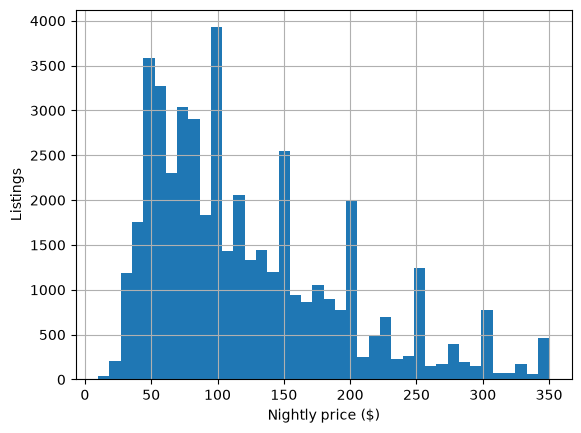

In [4]:
clean["price"].hist(bins=40)
plt.xlabel("Nightly price ($)")
plt.ylabel("Listings")
plt.show()


## Geographic boundaries
The pipeline tests that every listing lies inside NYC (longitude -74.25 to -73.50, latitude 40.5 to 41.2). Count listings outside that box. In `sample1.csv` there are none, so no boundary filter is applied here; the later `sample2.csv` batch contains such listings, which is why release 1.0.1 adds the filter to `basic_cleaning`.

In [5]:
in_nyc = clean["longitude"].between(-74.25, -73.50) & clean["latitude"].between(40.5, 41.2)
print(f"Listings outside NYC bounds: {(~in_nyc).sum()}")

Listings outside NYC bounds: 1


## Summary
- Prices outside the inclusive \$10–\$350 range are outliers and are removed in `basic_cleaning`.
- `last_review` is converted to a datetime.
- Missing values (`name`, `host_name`, `last_review`, `reviews_per_month`) are **not** imputed here; the inference pipeline imputes them so the same logic applies in production.

In [6]:
run.finish()

wandb: updating run metadata


wandb: uploading wandb-metadata.json; uploading requirements.txt; uploading output.log; uploading wandb-summary.json; uploading config.yaml


wandb: uploading config.yaml


wandb: uploading summary, console lines 0-0


wandb: 🚀 View run confused-meadow-36 at: https://wandb.ai/rand-alsweilm-udacity/nyc_airbnb/runs/fahxsogs
wandb: ⭐️ View project at: https://wandb.ai/rand-alsweilm-udacity/nyc_airbnb
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261015_120025-fahxsogs/logs
